<a href="https://colab.research.google.com/github/mahimakoulcs24/AI-LAB/blob/main/Forward_Chaining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== FOL Forward Chaining Solver ===

Step 1: Enter Initial Knowledge Base (Facts)
Example: [("American", "Robert"), ("Missile", "T1")]
Enter KB Facts:  [("American", "Robert"), ("Missile", "T1"), ("Owns", "Robert", "T1"), ("Sells", "Robert", "T1", "A"), ("Enemy", "America", "A")]

Step 2: Enter Inference Rules
Example: [([("Missile", "?x")], ("Weapon", "?x"))]
Enter Inference Rules:  [([("Missile", "?x")], ("Weapon", "?x")), ([("Enemy", "?c", "?s"), ("American", "?p"), ("Sells", "?p", "?w", "?s"), ("Weapon", "?w")], ("Criminal", "?p"))]

Step 3: Enter Target Goal
Example: ("Criminal", "Robert")
Enter Target Goal: ("Criminal", "Robert")

--- Processing Knowledge Base ---

--- Starting Forward Chaining Inference ---
Derived New Fact: ('Weapon', 'T1')
Derived New Fact: ('Criminal', 'Robert')
--- Inference Complete ---

SUCCESS: Goal ('Criminal', 'Robert') is proven!

Final Knowledge Base:
('American', 'Robert')
('Missile', 'T1')
('Owns', 'Robert', 'T1')
('Sells', 'Robert', 'T1', 'A')
('En

/tmp/ipykernel_332/2557540413.py:214: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


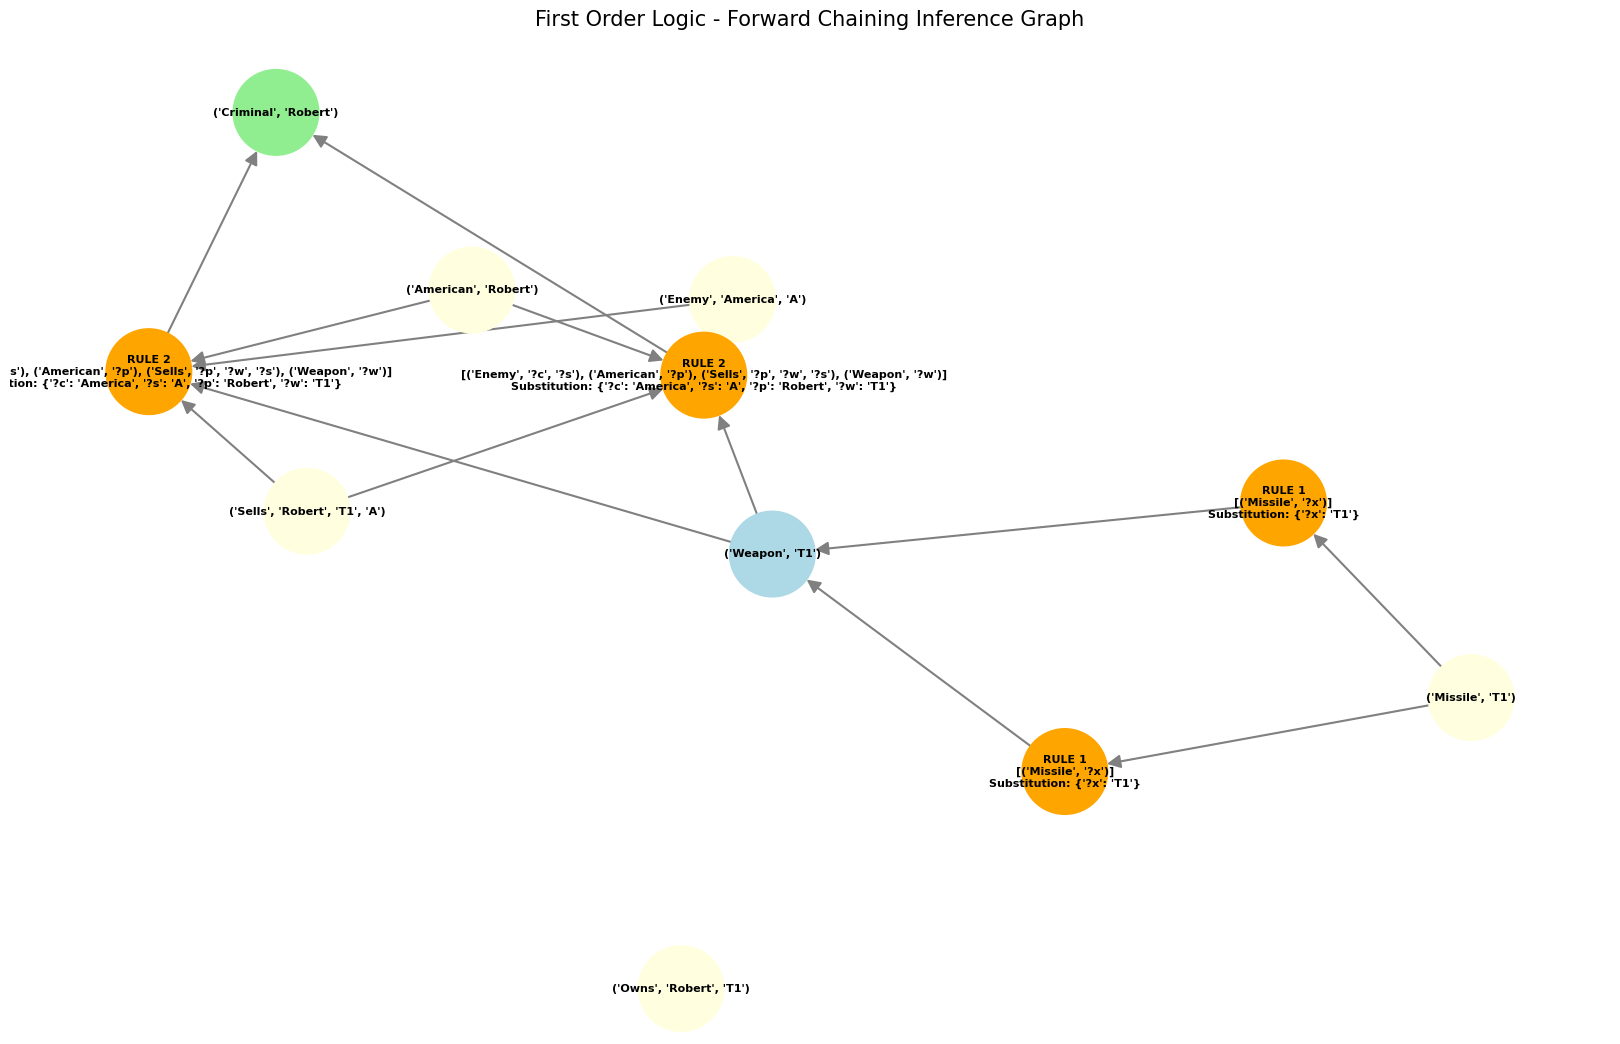

In [1]:
import ast
import networkx as nx
import matplotlib.pyplot as plt


# FOL Forward Chaining Class
class FOLForwardChaining:

    def __init__(self, initial_kb, rules):
        self.kb = list(initial_kb)
        self.rules = rules
        self.graph = nx.DiGraph()
        self.labels = {}
        self.initial_facts = set(initial_kb)
        self.derived_facts = set()

        # Add initial facts to graph
        for fact in initial_kb:
            self.graph.add_node(fact)
            self.labels[fact] = str(fact)


    # Unification
    def unify(self, pattern, fact, subst):

        if len(pattern) != len(fact):
            return None

        for p, f in zip(pattern, fact):

            if p.startswith("?"):
                if p in subst:
                    if subst[p] != f:
                        return None
                else:
                    subst[p] = f

            elif p != f:
                return None

        return subst


    # Match all conditions with facts
    def match_all(self, conditions, facts, subst=None, matched=None):

        if subst is None:
            subst = {}

        if matched is None:
            matched = []

        if not conditions:
            return [(subst, matched)]

        results = []
        first = conditions[0]
        remaining = conditions[1:]

        for fact in facts:

            new_subst = self.unify(first, fact, subst.copy())

            if new_subst is not None:

                results.extend(
                    self.match_all(
                        remaining,
                        facts,
                        new_subst,
                        matched + [fact]
                    )
                )

        return results


    # Apply substitution
    def apply_substitution(self, expression, subst):

        return tuple(
            subst.get(item, item) if item.startswith("?") else item
            for item in expression
        )


    # Forward Chaining
    def run(self, goal=None, verbose=True):

        derived = True

        if verbose:
            print("\n--- Starting Forward Chaining Inference ---")

        while derived:

            derived = False

            for i, (conditions, conclusion) in enumerate(self.rules):

                substitutions = self.match_all(conditions, self.kb)

                for subst, matched_facts in substitutions:

                    new_fact = self.apply_substitution(conclusion, subst)

                    # Create rule node for graph
                    rule_id = "Rule_" + str(i + 1) + "_" + str(len(self.graph))

                    rule_text = (
                        f"RULE {i + 1}\n"
                        f"{conditions}\n"
                        f"Substitution: {subst}"
                    )

                    self.graph.add_node(rule_id)
                    self.labels[rule_id] = rule_text

                    # Connect matched facts to rule
                    for fact in matched_facts:
                        self.graph.add_edge(fact, rule_id)

                    # Connect rule to conclusion
                    self.graph.add_node(new_fact)
                    self.labels[new_fact] = str(new_fact)

                    self.graph.add_edge(rule_id, new_fact)

                    # Add new fact only if not already present
                    if new_fact not in self.kb:

                        self.kb.append(new_fact)
                        self.derived_facts.add(new_fact)

                        if verbose:
                            print("Derived New Fact:", new_fact)

                        derived = True

        if verbose:
            print("--- Inference Complete ---\n")

        if goal is not None:

            success = goal in self.kb

            if verbose:
                if success:
                    print(f"SUCCESS: Goal {goal} is proven!")
                else:
                    print(f"FAILURE: Goal {goal} could not be proven.")

            return success, self.kb

        return self.kb


    # Generate Inference Graph
    def show_graph(self, goal):

        plt.figure(figsize=(16, 10))

        # Ensure goal appears in graph
        if goal not in self.graph:
            self.graph.add_node(goal)
            self.labels[goal] = str(goal)

        # Assign node colors
        colors = []

        for node in self.graph.nodes():

            if node == goal:
                colors.append("lightgreen")

            elif isinstance(node, str) and node.startswith("Rule_"):
                colors.append("orange")

            elif node in self.derived_facts:
                colors.append("lightblue")

            else:
                colors.append("lightyellow")

        # Graph layout
        pos = nx.spring_layout(
            self.graph,
            seed=42,
            k=2.0,
            iterations=200
        )

        nx.draw(
            self.graph,
            pos,
            labels=self.labels,
            with_labels=True,
            node_color=colors,
            node_size=3800,
            font_size=8,
            font_weight="bold",
            arrows=True,
            arrowsize=20,
            edge_color="gray",
            width=1.5
        )

        plt.title(
            "First Order Logic - Forward Chaining Inference Graph",
            fontsize=15
        )

        plt.axis("off")
        plt.tight_layout()
        plt.show()


# Parse user input
def parse_tuple_input(prompt_text):

    val = input(prompt_text).strip()

    try:
        return ast.literal_eval(val)

    except Exception as e:
        print("Invalid input. Please enter valid Python syntax.")
        print("Error:", e)
        return None


# Interactive Solver
def interactive_solver():

    print("=== FOL Forward Chaining Solver ===\n")

    # Step 1: Initial Knowledge Base
    print("Step 1: Enter Initial Knowledge Base (Facts)")
    print('Example: [("American", "Robert"), ("Missile", "T1")]')

    kb_input = None

    while kb_input is None:
        kb_input = parse_tuple_input("Enter KB Facts: ")

    # Step 2: Inference Rules
    print("\nStep 2: Enter Inference Rules")
    print('Example: [([("Missile", "?x")], ("Weapon", "?x"))]')

    rules_input = None

    while rules_input is None:
        rules_input = parse_tuple_input("Enter Inference Rules: ")

    # Step 3: Target Goal
    print("\nStep 3: Enter Target Goal")
    print('Example: ("Criminal", "Robert")')

    goal_input = None

    while goal_input is None:
        goal_input = parse_tuple_input("Enter Target Goal: ")

    # Step 4: Run Forward Chaining
    print("\n--- Processing Knowledge Base ---")

    engine = FOLForwardChaining(
        initial_kb=kb_input,
        rules=rules_input
    )

    success, final_kb = engine.run(
        goal=goal_input,
        verbose=True
    )

    # Step 5: Display Final Knowledge Base
    print("\nFinal Knowledge Base:")

    for fact in final_kb:
        print(fact)

    # Step 6: Generate Graph
    print("\n--- Generating Inference Graph ---")

    engine.show_graph(goal_input)


# Run the program ONCE
interactive_solver()